# 09 — Summary: every paper's method × every diabetes dataset

Reads `results/0[1-8]_*.csv` (run notebooks 01–08 first) and builds:
1. the main table (clean protocol): balanced accuracy, recall, specificity, AUC, with the
   majority-class rate as a floor;
2. paper-protocol vs clean-protocol gap (how much each paper's own protocol inflates the number);
3. paired tests of every model vs the RBF-SVM of notebook 08 on the **same** clean folds
   (Nadeau–Bengio corrected t-test on balanced accuracy, Holm correction within each dataset);
4. bootstrap 95 % CIs (B = 2000) for pooled paper-protocol accuracy;
5. a heatmap and `results/summary.md`.

Clean folds are identical across notebooks (same `clean_splits(dataset, seed)`), which is what
makes the fold-paired tests valid. Zhang (04) rows enter at noise rate 0 only.

In [1]:
import os, sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd() / "notebooks2", Path("/content/notebooks2"), *Path("/kaggle/input").glob("*"), *Path("/kaggle/input").glob("*/notebooks2")]:
    if (p / "nb2_common.py").exists():
        sys.path.insert(0, str(p)); break
from nb2_common import *
import matplotlib.pyplot as plt
RD = find_results_dir()
files = sorted(RD.glob("0[1-8]_*.csv"))
print("found:", [f.name for f in files])
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
if "noise_rate" in df:
    df = df[df.noise_rate.isna() | (df.noise_rate == 0)]
df["paper_model"] = df.paper.str.replace(r"^P0\d_", "", regex=True) + ": " + df.model
DATA = load_all()
FLOOR = {n: DATA[n]["majority_rate"] for n in DATASETS}

nb2_common loaded: numpy 2.4.6, sklearn 1.6.1
found: ['01_upama.csv', '02_young.csv', '03_kotha.csv', '04_zhang.csv', '05_kiran.csv', '06_sodar.csv', '07_yadav.csv', '08_daga.csv']
pima     N=  768 d=  8 prevalence=0.349 unique=  768 grouped_cv=False  [diabetes]
sylhet   N=  520 d= 16 prevalence=0.615 unique=  251 grouped_cv=True  [diabetes (early stage)]


cdc      N= 2000 d= 21 prevalence=0.140 unique= 1995 grouped_cv=True  [diabetes or prediabetes (self-reported)]


hosp130  N= 2000 d= 44 prevalence=0.088 unique= 2000 grouped_cv=False  [readmitted within 30 days]


## 1. Main table — clean protocol (mean over 3 seeds × 5 folds)

In [2]:
pd.set_option("display.width", 250, "display.max_rows", 300, "display.max_colwidth", 70)
clean = df[df.protocol == "clean"]
main = clean.groupby(["dataset", "paper_model"])[["balanced_accuracy", "recall", "specificity", "roc_auc", "accuracy"]].mean()
main["majority_floor"] = [FLOOR[d] for d in main.index.get_level_values(0)]
main = main.round(3).sort_values(["dataset", "balanced_accuracy"], ascending=[True, False])
main

balanced_accuracy  recall  specificity  roc_auc  accuracy  majority_floor
dataset paper_model                                                                                                                 
cdc     Kiran: RBF-SVM (same 4 PCs, balanced)                          0.727   0.786        0.669    0.798     0.686           0.860
        Kiran: Logistic Regression (same 4 PCs, balanced)              0.721   0.720        0.722    0.800     0.723           0.860
        Kotha: DiaBeats RF (threshold by inner CV)                     0.721   0.748        0.694    0.796     0.701           0.860
        Kiran: HQCAN VQC (4q, 2 layers)                                0.715   0.714        0.716    0.786     0.716           0.860
        Young: QISICGM ensemble (+GMM, train-fold only)                0.609   0.276        0.943    0.784     0.850           0.860
        Zhang: LightGBM + GIF weights                                  0.598   0.238        0.957    0.805     0.857           0.860
        Zhang: LightGBM                                                0.591   0.212        0.969    0.812     0.863           0.860
        Upama: RF (DML top-10)                                         0.584   0.206        0.961    0.769     0.856           0.860
        Daga: Logistic Regression                                      0.577   0.180        0.974    0.818     0.863           0.860
        Kotha: Logistic Regression                                     0.577   0.180        0.974    0.818     0.863           0.860
        Sodar: Logistic Regression                                     0.577   0.180        0.974    0.818     0.863           0.860
        Young: QISICGM ensemble (no augmentation)                      0.572   0.175        0.970    0.798     0.858           0.860
        Kotha: DiaBeats RF                                             0.559   0.138        0.981    0.796     0.863           0.860
        Daga: OOF-Stacking (LR meta)                                   0.558   0.133        0.982    0.756     0.863           0.860
        Upama: RF (all features)                                       0.553   0.124        0.981    0.796     0.861           0.860
        Daga: Random Forest                                            0.551   0.120        0.983    0.801     0.862           0.860
        Daga: RBF-SVM                                                  0.531   0.071        0.990    0.750     0.862           0.860
        Sodar: RBF-SVM                                                 0.531   0.071        0.990    0.750     0.862           0.860
        Yadav: RBF-SVM                                                 0.531   0.071        0.990    0.750     0.862           0.860
        Yadav: ZZ-QSVM (full) bw=inner-CV                              0.527   0.062        0.991    0.700     0.861           0.860
        Yadav: ZZ-QSVM (linear) bw=inner-CV                            0.520   0.049        0.992    0.704     0.860           0.860
        Yadav: Z-QSVM bw=1                                             0.513   0.032        0.995    0.708     0.860           0.860
        Yadav: Z-QSVM bw=inner-CV                                      0.513   0.032        0.994    0.700     0.860           0.860
        Daga: ZZ-QSVM                                                  0.506   0.014        0.998    0.684     0.860           0.860
        Yadav: ZZ-QSVM (linear) bw=1                                   0.506   0.014        0.998    0.684     0.860           0.860
        Upama: Angle-QSVM (DML top-10)                                 0.501   0.004        0.998    0.729     0.859           0.860
        Yadav: ZZ-QSVM (full) bw=1                                     0.501   0.001        1.000    0.635     0.861           0.860
        Daga: Amplitude-QSVM                                           0.500   0.000        1.000    0.692     0.860           0.860
        Daga: Angle-QSVM                                             

## 2. Paper protocol vs clean protocol (accuracy; positive gap = paper protocol looks better)

In [3]:
proto = df[df.protocol.isin(["paper", "clean"])].groupby(["dataset", "paper_model", "protocol"])["accuracy"].mean().unstack()
proto = proto.dropna()
proto["gap (paper - clean)"] = proto["paper"] - proto["clean"]
proto.round(3).sort_values("gap (paper - clean)", ascending=False)

protocol                                                   clean  paper  gap (paper - clean)
dataset paper_model                                                                         
sylhet  Yadav: ZZ-QSVM (full) bw=1                         0.721  0.942                0.222
        Yadav: ZZ-QSVM (linear) bw=1                       0.733  0.952                0.219
        Daga: ZZ-QSVM                                      0.733  0.933                0.200
        Yadav: Z-QSVM bw=1                                 0.790  0.981                0.190
        Daga: Amplitude-QSVM                               0.823  0.919                0.096
        Zhang: LightGBM + GIF weights                      0.869  0.962                0.093
        Sodar: Amplitude-QSVM (standardised)               0.823  0.910                0.087
        Zhang: LightGBM                                    0.892  0.971                0.079
        Upama: Linear SVM (DML top-10)                     0.864  0.942                0.078
        Upama: RF (all features)                           0.924  0.990                0.066
        Kotha: DiaBeats RF                                 0.925  0.990                0.066
        Upama: RF (DML top-10)                             0.918  0.981                0.063
        Daga: Hard-Voting (4 kernels)                      0.907  0.967                0.060
        Daga: Angle-QSVM                                   0.888  0.948                0.060
        Sodar: Angle-QSVM                                  0.888  0.942                0.054
        Yadav: RBF-SVM                                     0.928  0.981                0.053
        Kiran: Logistic Regression (same 4 PCs, balanced)  0.871  0.923                0.052
        Daga: Random Forest                                0.930  0.981                0.051
        Kiran: Angle-QSVM (same 4 PCs)                     0.901  0.952                0.051
        Kotha: Logistic Regression                         0.893  0.942                0.049
        Kiran: HQCAN VQC (4q, 2 layers)                    0.740  0.788                0.048
        Daga: RBF-SVM                                      0.928  0.973                0.045
        Daga: OOF-Stacking (LR meta)                       0.924  0.963                0.040
        Upama: Angle-QSVM (DML top-10)                     0.902  0.942                0.040
        Daga: Logistic Regression                          0.893  0.929                0.035
        Sodar: Amplitude-QSVM (MinMax, paper)              0.915  0.949                0.033
        Sodar: RBF-SVM                                     0.928  0.962                0.033
        Kiran: RBF-SVM (same 4 PCs, balanced)              0.901  0.933                0.032
        Sodar: Logistic Regression                         0.893  0.923                0.030
cdc     Upama: RF (DML top-10)                             0.856  0.878                0.022
pima    Sodar: Amplitude-QSVM (standardised)               0.648  0.667                0.019
cdc     Kiran: RBF-SVM (same 4 PCs, balanced)              0.686  0.705                0.019
        Kiran: HQCAN VQC (4q, 2 layers)                    0.716  0.732                0.016
        Kiran: Logistic Regression (same 4 PCs, balanced)  0.723  0.735                0.012
        Kotha: DiaBeats RF                                 0.863  0.875                0.012
        Upama: RF (all features)                           0.861  0.872                0.011
pima    Upama: RF (DML top-7)                              0.769  0.779                0.010
hosp130 Upama: RF (DML top-10)                             0.904  0.912                0.009
pima    Daga: Random Forest                                0.760  0.767                0.007
cdc     Yadav: RBF-SVM                                     0.862  0.868                0.006
        Yadav: Z-QSVM bw=1                                 0.860  0.865                0.005
p

## 3. Fold-paired tests vs RBF-SVM (notebook 08), balanced accuracy, Holm within dataset

In [4]:
ref = clean[(clean.paper == "P08_Daga") & (clean.model == "RBF-SVM")].set_index(["dataset", "seed", "fold"])["balanced_accuracy"]
tests = []
for (dset, pm), g in clean.groupby(["dataset", "paper_model"]):
    if pm == "Daga: RBF-SVM":
        continue
    g = g.set_index(["dataset", "seed", "fold"])["balanced_accuracy"]
    g = g[~g.index.duplicated()]
    common = g.index.intersection(ref.index)
    d = (g.loc[common] - ref.loc[common]).values
    n = len(DATA[dset]["y"]); n_te = n / N_SPLITS
    t, p = nadeau_bengio(d, n - n_te, n_te)
    tests.append(dict(dataset=dset, model=pm, n_pairs=len(d), mean_diff=np.mean(d), t=t, p=p))
tests = pd.DataFrame(tests)
tests["p_holm"] = np.nan
for dset, g in tests.groupby("dataset"):
    tests.loc[g.index, "p_holm"] = holm(g.p.values)
tests["verdict"] = np.where(tests.p_holm < 0.05, np.where(tests.mean_diff > 0, "better", "worse"), "n.s.")
tests.round(4).sort_values(["dataset", "mean_diff"], ascending=[True, False])

,dataset,model,n_pairs,mean_diff,t,p,p_holm,verdict
11,cdc,"Kiran: RBF-SVM (same 4 PCs, balanced)",15,0.1967,8.9269,0.0000,0.0000,better
10,cdc,"Kiran: Logistic Regression (same 4 PCs, balanced)",15,0.1902,8.8711,0.0000,0.0000,better
13,cdc,Kotha: DiaBeats RF (threshold by inner CV),15,0.1898,8.5395,0.0000,0.0000,better
9,cdc,"Kiran: HQCAN VQC (4q, 2 layers)",15,0.1843,8.6084,0.0000,0.0000,better
32,cdc,"Young: QISICGM ensemble (+GMM, train-fold only)",15,0.0787,4.6493,0.0004,0.0120,better
35,cdc,Zhang: LightGBM + GIF weights,15,0.0669,4.0719,0.0011,0.0297,better
34,cdc,Zhang: LightGBM,15,0.0599,4.4719,0.0005,0.0142,better
23,cdc,Upama: RF (DML top-10),15,0.0529,4.6148,0.0004,0.0120,better
3,cdc,Daga: Logistic Regression,15,0.0463,4.6514,0.0004,0.0120,better
14,cdc,Kotha: Logistic Regression,15,0.0463,4.6514,0.0004,0.0120,better


## 4. Bootstrap 95 % CI of pooled paper-protocol accuracy (rows rebuilt from confusion counts)

In [5]:
ci = []
rng = np.random.RandomState(42)
for (dset, pm), g in df[df.protocol == "paper"].groupby(["dataset", "paper_model"]):
    tp, tn, fp, fn = (int(g[c].sum()) for c in ["tp", "tn", "fp", "fn"])
    y = np.r_[np.ones(tp + fn), np.zeros(tn + fp)].astype(int)
    pr = np.r_[np.ones(tp), np.zeros(fn), np.zeros(tn), np.ones(fp)].astype(int)
    acc = (y == pr).mean()
    boots = [(y[i] == pr[i]).mean() for i in (rng.randint(0, len(y), len(y)) for _ in range(2000))]
    ci.append(dict(dataset=dset, model=pm, n=len(y), accuracy=acc,
                   ci_low=np.percentile(boots, 2.5), ci_high=np.percentile(boots, 97.5)))
ci = pd.DataFrame(ci).round(4)
ci

,dataset,model,n,accuracy,ci_low,ci_high
0,cdc,Daga: Amplitude-QSVM,2000,0.8605,0.8455,0.8755
1,cdc,Daga: Angle-QSVM,2000,0.8605,0.8450,0.8755
2,cdc,Daga: Hard-Voting (4 kernels),2000,0.8605,0.8450,0.8765
3,cdc,Daga: Logistic Regression,2000,0.8575,0.8420,0.8725
4,cdc,Daga: Majority class,2000,0.8605,0.8450,0.8755
5,cdc,Daga: OOF-Stacking (LR meta),2000,0.8645,0.8485,0.8790
6,cdc,Daga: RBF-SVM,2000,0.8625,0.8480,0.8770
7,cdc,Daga: Random Forest,2000,0.8665,0.8515,0.8815
8,cdc,Daga: ZZ-QSVM,2000,0.8605,0.8455,0.8755
9,cdc,Kiran: Angle-QSVM (same 4 PCs),400,0.8600,0.8250,0.8950


## 5. Heatmap — clean balanced accuracy

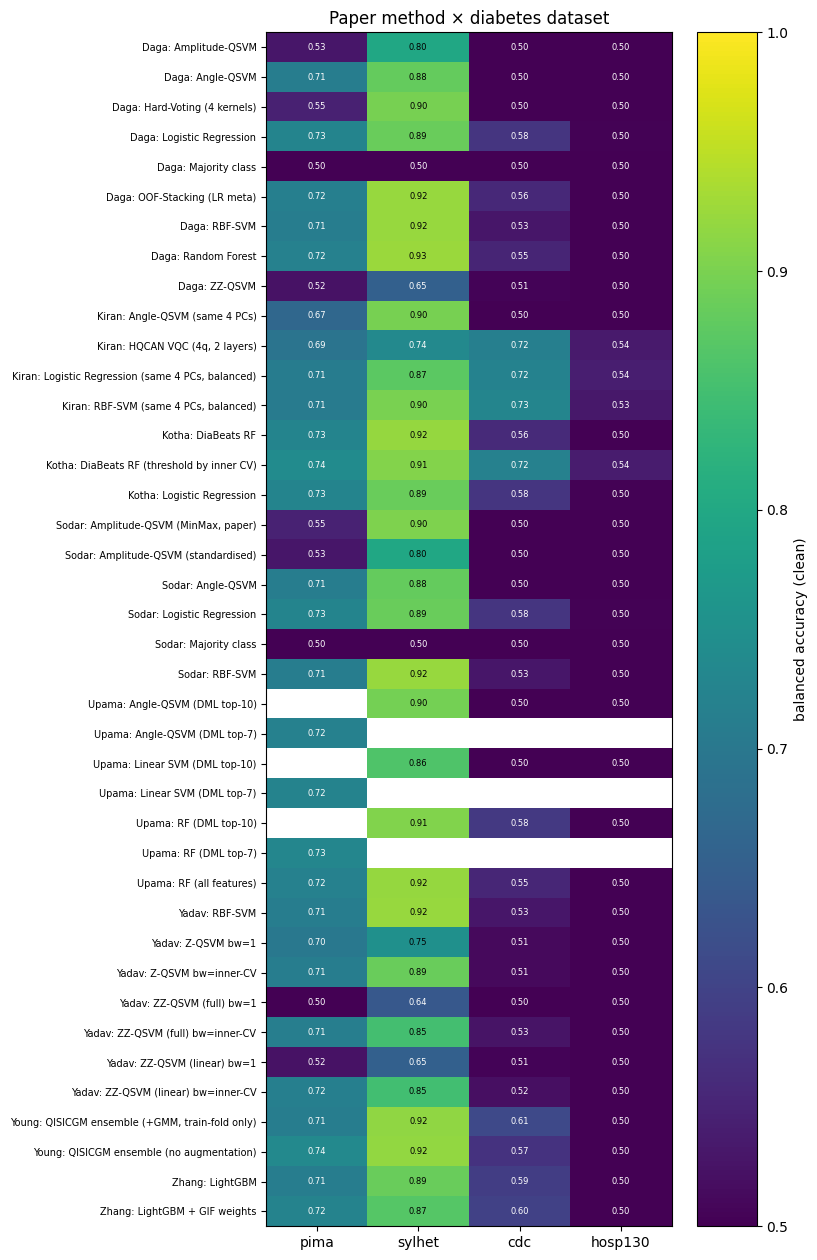

In [6]:
hm = clean.groupby(["paper_model", "dataset"])["balanced_accuracy"].mean().unstack()[DATASETS]
fig, ax = plt.subplots(figsize=(8, 0.28 * len(hm) + 1.5))
im = ax.imshow(hm.values, cmap="viridis", aspect="auto", vmin=0.5, vmax=1.0)
ax.set_xticks(range(len(DATASETS)), DATASETS); ax.set_yticks(range(len(hm)), hm.index, fontsize=7)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="w" if v < 0.75 else "k")
plt.colorbar(im, label="balanced accuracy (clean)"); plt.title("Paper method × diabetes dataset")
plt.tight_layout(); plt.savefig(RD / "09_heatmap_balanced_accuracy.png", dpi=160); plt.show()

## 6. Write `results/summary.md` (all numbers come from the tables above)

In [7]:
def md(t):
    try:
        return t.to_markdown()
    except ImportError:
        return "```\n" + t.to_string() + "\n```"

with open(RD / "summary.md", "w", encoding="utf-8") as f:
    f.write("# notebooks2 summary — paper methods × diabetes datasets\n\n")
    f.write("Positive class: " + "; ".join(f"{n}: {DATA[n]['positive']}" for n in DATASETS) + "\n\n")
    f.write("## Clean protocol (mean over seeds × folds)\n\n" + md(main) + "\n\n")
    f.write("## Paper vs clean protocol (accuracy)\n\n" + md(proto.round(3)) + "\n\n")
    f.write("## Paired tests vs RBF-SVM (balanced accuracy, Nadeau-Bengio, Holm per dataset)\n\n" + md(tests.round(4)) + "\n\n")
    f.write("## Paper-protocol pooled accuracy, bootstrap 95 % CI\n\n" + md(ci) + "\n")
print("wrote", RD / "summary.md")

wrote /content/notebooks2/results/summary.md
